# 06 — Pemët e vendimit dhe metodat ansambël

        **Pyetja udhëheqëse:** Si ndërtohet një vendim me rregulla dhe si stabilizohet me shumë pemë?

        Ky notebook është ndërtuar si një mësim i plotë kompjuterik. Rruga kryesore ndjek:
        **problem konkret → model matematikor → zbatim nga parimet e para → bibliotekë profesionale → krahasim → interpretim**.

        ## Objektivat
        - Të kuptohen Gini, entropia dhe fitimi i informacionit.
- Të analizohet thellësia dhe mbipërshtatja.
- Të krahasohet një pemë me Random Forest.
- Të interpretohen rëndësitë e veçorive.

        > **Rruga bazë për orën mësimore (45–60 min)** shënohet me seksionet **CORE**.  
        > Seksionet **EXTENDED** dhe **PLAYGROUND** janë për thellim dhe punë të pavarur.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import time

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("06 — Pemët e vendimit dhe metodat ansambël")
print("Seed:", RANDOM_STATE)

06 — Pemët e vendimit dhe metodat ansambël
Seed: 42


# 1. Klasifikimi i fazave të një materiali — CORE

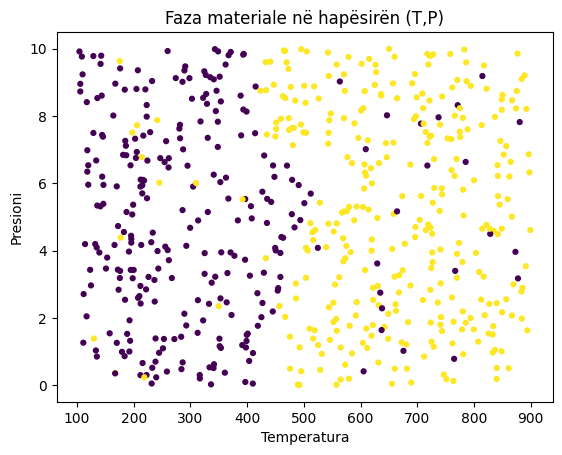

In [2]:
n=600
T=rng.uniform(100,900,n)
P=rng.uniform(0,10,n)
phase=((T>500+18*(P-5)) | ((T>420)&(P>7))).astype(int)
flip=rng.random(n)<0.07
phase[flip]=1-phase[flip]
X=np.c_[T,P]; y=phase
fig,ax=plt.subplots()
ax.scatter(T,P,c=y,s=12)
ax.set_xlabel("Temperatura"); ax.set_ylabel("Presioni")
ax.set_title("Faza materiale në hapësirën (T,P)")
plt.show()

# 2. Gini dhe entropia — CORE

Për probabilitete klase $p_k$,
$$
G=1-\sum_k p_k^2,\qquad
H=-\sum_k p_k\log_2 p_k.
$$
Një ndarje e mirë redukton papastërtinë e nyjeve pasardhëse.

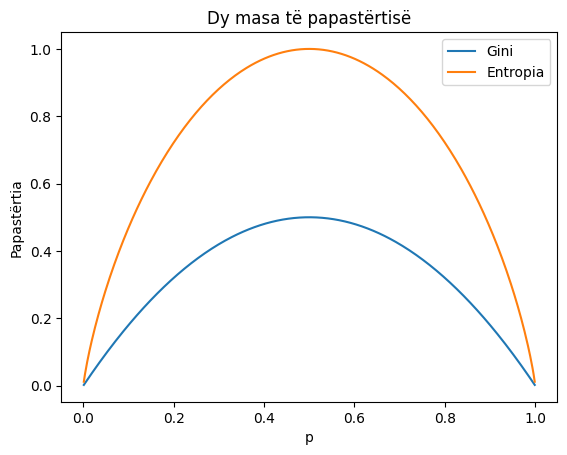

In [3]:
p=np.linspace(0.001,0.999,400)
g=1-(p**2+(1-p)**2)
h=-(p*np.log2(p)+(1-p)*np.log2(1-p))
fig,ax=plt.subplots()
ax.plot(p,g,label="Gini")
ax.plot(p,h,label="Entropia")
ax.set_xlabel("p"); ax.set_ylabel("Papastërtia")
ax.legend(); ax.set_title("Dy masa të papastërtisë")
plt.show()

# 3. Një pemë e vetme — CORE

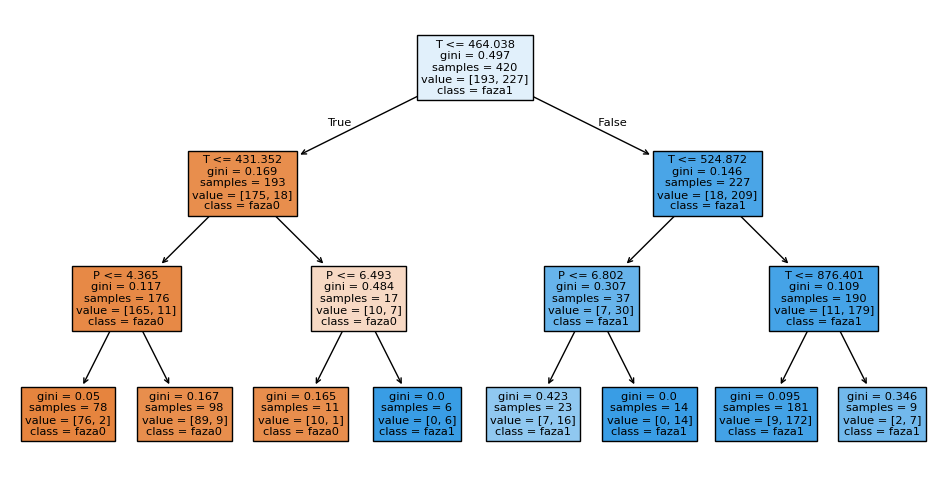

In [4]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.3,stratify=y,random_state=RANDOM_STATE)
tree=DecisionTreeClassifier(max_depth=3,random_state=RANDOM_STATE).fit(Xtr,ytr)
fig,ax=plt.subplots(figsize=(12,6))
plot_tree(tree,feature_names=["T","P"],class_names=["faza0","faza1"],filled=True,ax=ax)
plt.show()

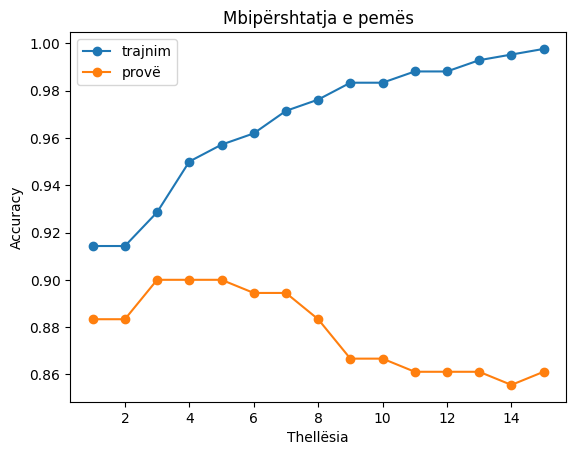

In [5]:
depths=range(1,16)
tr=[DecisionTreeClassifier(max_depth=d,random_state=RANDOM_STATE).fit(Xtr,ytr).score(Xtr,ytr) for d in depths]
te=[DecisionTreeClassifier(max_depth=d,random_state=RANDOM_STATE).fit(Xtr,ytr).score(Xte,yte) for d in depths]
fig,ax=plt.subplots()
ax.plot(list(depths),tr,marker="o",label="trajnim")
ax.plot(list(depths),te,marker="o",label="provë")
ax.set_xlabel("Thellësia"); ax.set_ylabel("Accuracy"); ax.legend()
ax.set_title("Mbipërshtatja e pemës")
plt.show()

# 4. Random Forest: bagging dhe rastësi në veçori — CORE

In [6]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier(n_estimators=250,random_state=RANDOM_STATE).fit(Xtr,ytr)
print("Tree:",tree.score(Xte,yte),"RF:",rf.score(Xte,yte))

Tree: 0.9 RF: 0.9166666666666666


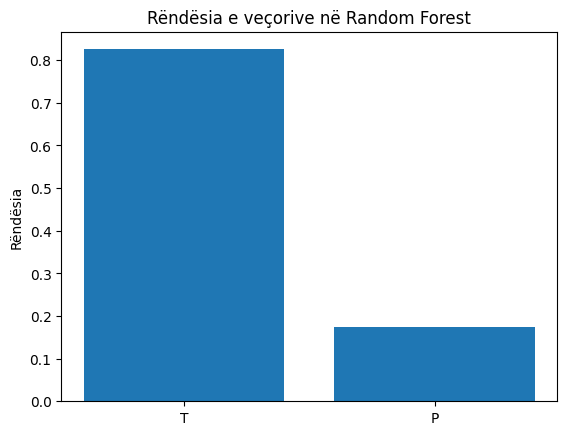

In [7]:
fig,ax=plt.subplots()
ax.bar(["T","P"],rf.feature_importances_)
ax.set_ylabel("Rëndësia")
ax.set_title("Rëndësia e veçorive në Random Forest")
plt.show()

# 5. Permutation importance — CORE

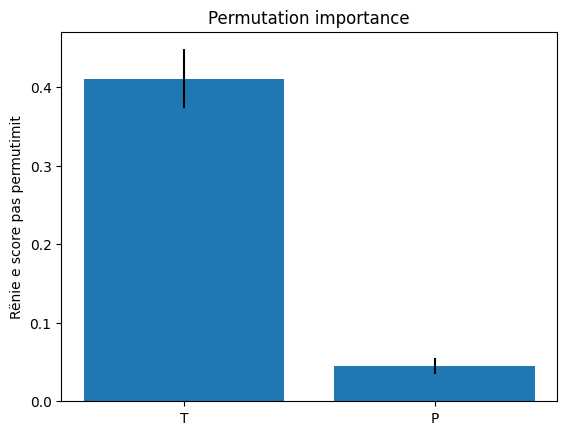

In [8]:
from sklearn.inspection import permutation_importance
perm=permutation_importance(rf,Xte,yte,n_repeats=30,random_state=RANDOM_STATE)
fig,ax=plt.subplots()
ax.bar(["T","P"],perm.importances_mean,yerr=perm.importances_std)
ax.set_ylabel("Rënie e score pas permutimit")
ax.set_title("Permutation importance")
plt.show()

---
## Deri këtu: materiali bazë për orën mësimore

Në një seancë rreth 60 minuta, zakonisht ndalemi këtu. Seksionet që vijojnë janë për thellim,
ushtrime të pavarura dhe eksperimentim.

# 6. Boosting: ideja — EXTENDED

Në boosting, modelet ndërtohen sekuencialisht dhe secili përpiqet të korrigjojë gabimet e ansamblit
të deritanishëm. Kjo është ndryshe nga bagging, ku modelet mund të ndërtohen paralelisht mbi mostra
bootstrap.

In [9]:
from sklearn.ensemble import GradientBoostingClassifier
gb=GradientBoostingClassifier(random_state=RANDOM_STATE).fit(Xtr,ytr)
print("Gradient Boosting test accuracy:",gb.score(Xte,yte))

Gradient Boosting test accuracy: 0.9


# 7. Aplikim jo-fizik: vlerësim rreziku — EXTENDED

Pemët janë tërheqëse në fusha ku rregullat e vendimit duhet të shpjegohen, si sigurimet ose triage mjekësor. Megjithatë, interpretueshmëria e një peme nuk transferohet automatikisht te një pyll me qindra pemë.

# Ushtrime — PLAYGROUND

        ## A. Ushtrime të shkurtra
        1. Llogaritni Gini për një nyje me raport klasash 70:30.
2. Krahasoni `max_depth=2` dhe `max_depth=None`.
3. Shtoni një veçori zhurmë dhe analizoni rëndësinë e saj.
4. Krahasoni impurity-based dhe permutation importance.

        ## B. Ushtrim i plotë
        Ndërtoni një klasifikues fazash me 3 klasa dhe analizoni kufijtë e vendimit të një peme dhe Random Forest.

        ## C. Playground
        Ndryshoni thellësinë, numrin e pemëve, zhurmën e etiketave dhe seed.

In [10]:
# TODO / PLAYGROUND
# Ndryshoni parametrat, shtoni grafikë ose krahasoni modele të tjera.

### Zgjidhje orientuese për instruktorin
- Për raport 70:30, $G=1-(0.7^2+0.3^2)=0.42$.
- Pemët e thella priren të mbipërshtaten; Random Forest ul variancën duke mesatarizuar pemë të dekorreluara.
- Rëndësia e veçorive nuk është provë shkakësie dhe mund të ndikohet nga korrelacionet mes veçorive.